## 1. Load the data to pandas and let's look at the shape of this dataset

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings

warnings.simplefilter("ignore")
%matplotlib inline

red_data = pd.read_csv("winequality-red.csv", sep=";")
white_data = pd.read_csv("winequality-white.csv", sep=";")
red_data.shape

(1599, 12)

### and the shape of white_data:

In [2]:
white_data.shape

(4898, 12)

### concatenate into a single dataset

In [3]:
red_data["type"] = 0
white_data["type"] = 1

all_data = pd.concat([red_data, white_data], ignore_index=True)
all_data.shape

(6497, 13)

### let's look at the quality distribution

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


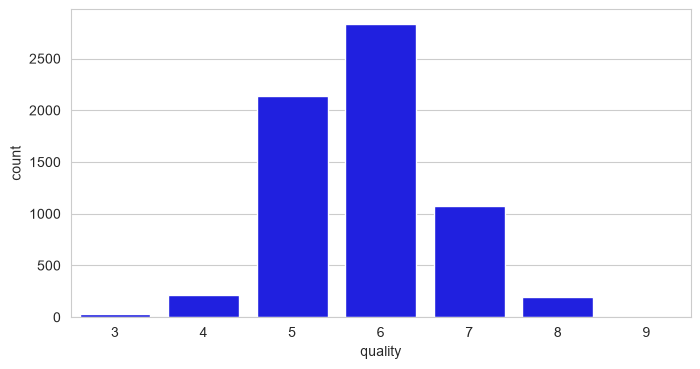

In [4]:
print(all_data["quality"].value_counts().sort_index())

plt.figure(figsize=(8, 4))
sns.countplot(data=all_data, x="quality", color="blue")
plt.show()

In [5]:
print("Mean quality in red vine:", all_data[all_data["type"] == 0]["quality"].mean().round(2))
print("Mean quality in white vine:", all_data[all_data["type"] == 1]["quality"].mean().round(2))

Mean quality in red vine: 5.64
Mean quality in white vine: 5.88


### split dataset 60/20/20 - train/validation/test

In [7]:
from sklearn.model_selection import train_test_split

X = all_data.drop(columns="quality")
y = all_data["quality"]

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (3897, 12)
Validation: (1300, 12)
Test: (1300, 12)


**Split:** 60% train, 20% validation, 20% test. Stratification keeps the quality distribution similar. Test data is used only at the end.

## 2. Define the correlations between alcohol and quality

Correlations with quality:
density                -0.311
volatile acidity       -0.270
chlorides              -0.200
fixed acidity          -0.090
total sulfur dioxide   -0.042
residual sugar         -0.031
pH                      0.032
sulphates               0.037
free sulfur dioxide     0.060
citric acid             0.073
type                    0.124
alcohol                 0.441
Name: quality, dtype: float64


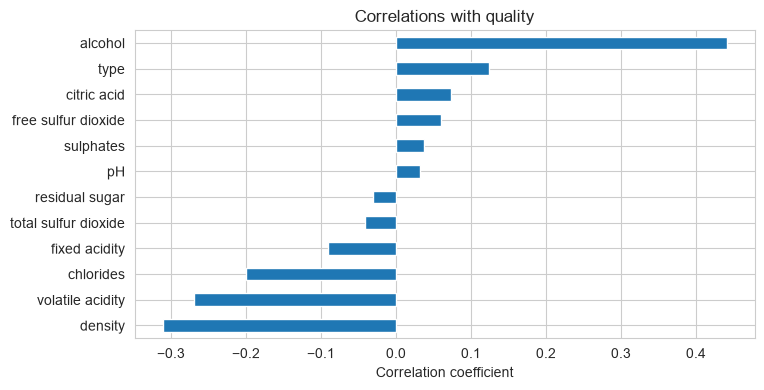

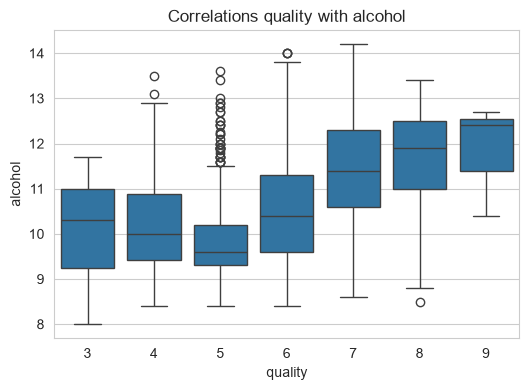

In [8]:
train_data = X_train.copy()
train_data["quality"] = y_train

correlations = train_data.corr()["quality"].drop("quality").sort_values()
print("Correlations with quality:")
print(correlations.round(3))

plt.figure(figsize=(8, 4))
correlations.plot(kind="barh")
plt.title("Correlations with quality")
plt.xlabel("Correlation coefficient")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=train_data, x="quality", y="alcohol")
plt.title("Correlations quality with alcohol")
plt.show()

Alcohol has the strongest positive correlation with quality; density and volatile acidity have negative correlations. Most wines have quality 5–6.

## 3. Baseline + three models

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

baseline_value = y_train.mean()
print(baseline_value)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

forest_model = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)
forest_model.fit(X_train, y_train)

boosting_model = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
boosting_model.fit(X_train, y_train)

print("All three models are trained!")

5.818321785989222
All three models are trained!


In [37]:
val_predictions = {
    "Baseline": np.full(len(y_val), baseline_value),
    "Linear Regression": linear_model.predict(X_val_scaled),
    "Random Forest": forest_model.predict(X_val),
    "Gradient Boosting": boosting_model.predict(X_val)
}

val_results = []
for model_name, predictions in val_predictions.items():
    val_results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "MAE": mean_absolute_error(y_val, predictions)
    })

validation_table = pd.DataFrame(val_results).sort_values("RMSE")
print("Results on the validation set:")
display(validation_table.round(3))

Results on the validation set:


,Model,RMSE,MAE
2,Random Forest,0.646,0.472
3,Gradient Boosting,0.691,0.539
1,Linear Regression,0.748,0.583
0,Baseline,0.872,0.685


## 4. Linear regression coefficients after scaler

density                -0.402
volatile acidity       -0.246
type                   -0.156
total sulfur dioxide   -0.091
citric acid            -0.022
chlorides              -0.015
free sulfur dioxide     0.096
sulphates               0.114
pH                      0.115
fixed acidity           0.153
alcohol                 0.225
residual sugar          0.361
dtype: float64


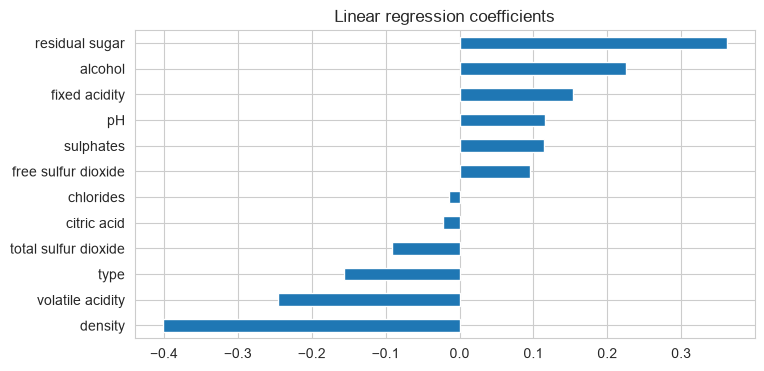

In [11]:
linear_coef = pd.Series(linear_model.coef_, index=X.columns).sort_values()
print(linear_coef.round(3))

plt.figure(figsize=(8, 4))
linear_coef.plot(kind="barh")
plt.title("Linear regression coefficients")
plt.show()

## 5. Feature importance

In [12]:
forest_importance = pd.Series(forest_model.feature_importances_, index=X.columns).sort_values()
boosting_importance = pd.Series(boosting_model.feature_importances_, index=X.columns).sort_values()

print("Random Forest top features:")
print(forest_importance.sort_values(ascending=False).head(5).round(3))
print("\nGradient Boosting top features:")
print(boosting_importance.sort_values(ascending=False).head(5).round(3))

Random Forest top features:
alcohol                0.251
volatile acidity       0.140
free sulfur dioxide    0.091
sulphates              0.075
residual sugar         0.072
dtype: float64

Gradient Boosting top features:
alcohol                0.422
volatile acidity       0.192
free sulfur dioxide    0.097
sulphates              0.066
residual sugar         0.060
dtype: float64


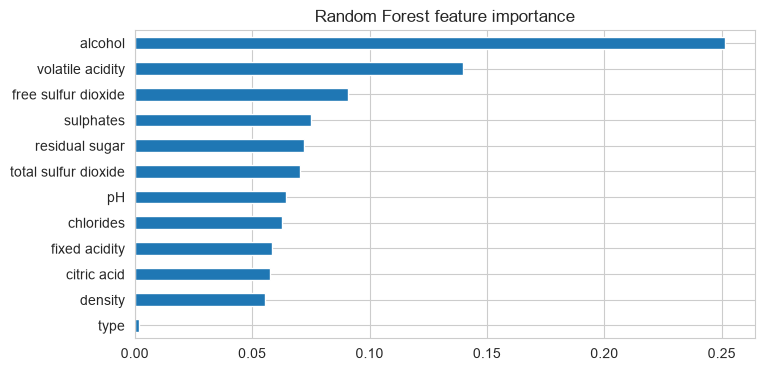

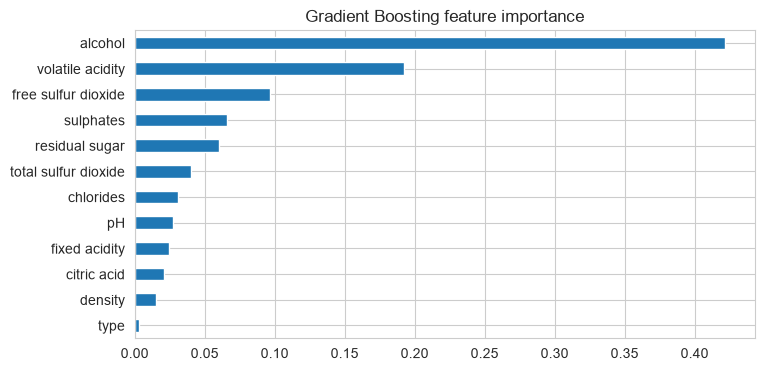

In [13]:
plt.figure(figsize=(8, 4))
forest_importance.plot(kind="barh")
plt.title("Random Forest feature importance")
plt.show()

plt.figure(figsize=(8, 4))
boosting_importance.plot(kind="barh")
plt.title("Gradient Boosting feature importance")
plt.show()

**Note:** Feature importance does not prove causation.

## 6. Final test

In [32]:
best_model_name = validation_table.iloc[0]["Model"]
print("Chosen on validation:", best_model_name)

final_scaler = StandardScaler()
X_train_val_scaled = final_scaler.fit_transform(X_train_val)
X_test_scaled = final_scaler.transform(X_test)

final_linear = LinearRegression()
final_linear.fit(X_train_val_scaled, y_train_val)

final_forest = RandomForestRegressor(n_estimators=450, random_state=42, n_jobs=-1)
final_forest.fit(X_train_val, y_train_val)

final_boosting = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
final_boosting.fit(X_train_val, y_train_val)

Chosen on validation: Random Forest


,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",500
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

In [33]:
test_predictions = {
    "Baseline": np.full(len(y_test), y_train_val.mean()),
    "Linear Regression": final_linear.predict(X_test_scaled),
    "Random Forest": final_forest.predict(X_test),
    "Gradient Boosting": final_boosting.predict(X_test)
}

test_results = []
for model_name, predictions in test_predictions.items():
    test_results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions)
    })

test_table = pd.DataFrame(test_results).sort_values("RMSE")
display(test_table.round(3))

,Model,RMSE,MAE
2,Random Forest,0.605,0.430
3,Gradient Boosting,0.667,0.520
1,Linear Regression,0.728,0.568
0,Baseline,0.874,0.686


## 7. Error analysis on Random Forest model

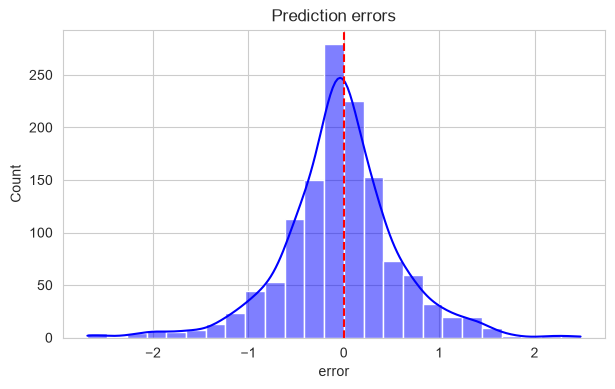

In [38]:
best_predictions = test_predictions[best_model_name]
errors_table = pd.DataFrame({"quality": y_test, "prediction": best_predictions}, index=y_test.index)
errors_table["error"] = errors_table["quality"] - errors_table["prediction"]
errors_table["absolute_error"] = errors_table["error"].abs()

plt.figure(figsize=(7, 4))
sns.histplot(errors_table["error"], bins=25, kde=True, color="blue")
plt.axvline(0, color="red", linestyle="--")
plt.title("Prediction errors")
plt.show()

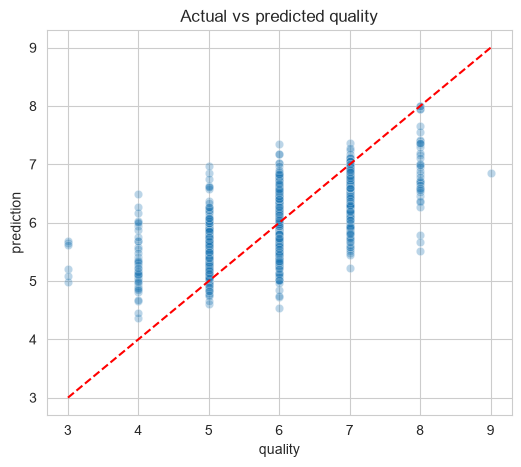

In [39]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=errors_table, x="quality", y="prediction", alpha=0.3)
plt.plot([3, 9], [3, 9], "r--")
plt.title("Actual vs predicted quality")
plt.show()

In [40]:
print("Largest errors:")
display(errors_table.sort_values("absolute_error", ascending=False).head(10).round(2))

worst_indices = errors_table.nlargest(5, "absolute_error").index
worst_wines = X_test.loc[worst_indices].copy()
worst_wines["quality"] = y_test.loc[worst_indices]
worst_wines["prediction"] = errors_table.loc[worst_indices, "prediction"]
display(worst_wines.round(2))

Largest errors:


,quality,prediction,error,absolute_error
2339,3,5.69,-2.69,2.69
3287,3,5.64,-2.64,2.64
1850,3,5.62,-2.62,2.62
6107,4,6.49,-2.49,2.49
3005,8,5.52,2.48,2.48
1403,8,5.67,2.33,2.33
3718,4,6.26,-2.26,2.26
440,8,5.79,2.21,2.21
1469,3,5.20,-2.20,2.20
3715,4,6.17,-2.17,2.17


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality,prediction
2339,6.9,0.39,0.40,4.60,0.02,5.0,19.0,0.99,3.31,0.37,12.6,1,3,5.69
3287,6.7,0.25,0.26,1.55,0.04,118.5,216.0,0.99,3.55,0.63,9.4,1,3,5.64
1850,8.5,0.26,0.21,16.20,0.07,41.0,197.0,1.00,3.02,0.50,9.8,1,3,5.62
6107,5.8,0.26,0.30,2.60,0.03,75.0,129.0,0.99,3.20,0.38,11.5,1,4,6.49
3005,8.2,0.22,0.36,6.80,0.03,12.0,90.0,0.99,3.01,0.38,10.5,1,8,5.52


,count,mean
quality,,
3,6,2.370
4,43,1.312
5,428,0.384
6,567,0.310
7,216,0.479
8,39,1.077
9,1,2.156


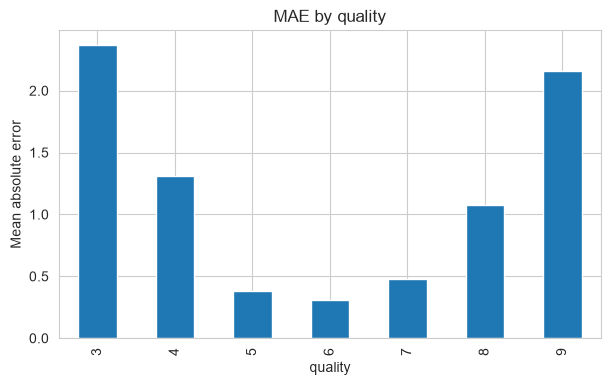

In [41]:
quality_errors = errors_table.groupby("quality")["absolute_error"].agg(["count", "mean"])
display(quality_errors.round(3))

plt.figure(figsize=(7, 4))
quality_errors["mean"].plot(kind="bar")
plt.title("MAE by quality")
plt.ylabel("Mean absolute error")
plt.show()

## 8. Notes

- Most wines have quality 5–6.
- Alcohol is positively correlated with quality, while density and volatile acidity are negatively correlated.
- Compare linear coefficients and tree importances: they measure different things.
- Rare quality scores may be harder to predict because there are fewer examples.